# Trabajo Integrador Final – Análisis del Mercado Inmobiliario

## Introducción

El presente trabajo tiene como objetivo realizar un análisis exploratorio y estadístico de un dataset relacionado con el mercado inmobiliario.

La base de datos contiene información de propiedades ubicadas en distintos barrios y localidades de la Ciudad Autónoma de Buenos Aires (CABA) y la Provincia de Buenos Aires, incluyendo variables como fecha, tipo de propiedad, tipo de operación, precio, superficie, cantidad de ambientes, expensas, estado de la propiedad, amenities, cochera y antigüedad.

El objetivo del análisis será explorar la información disponible, evaluar la calidad de los datos e identificar patrones y diferencias entre las propiedades analizadas.

A lo largo del trabajo se realizarán tareas de limpieza, transformación y análisis de los datos utilizando Python y la librería Pandas.

## Objetivos

- Analizar la estructura y calidad del dataset.
- Detectar valores faltantes, duplicados y posibles inconsistencias.
- Obtener estadísticas descriptivas de las principales variables.
- Analizar precios y valores por metro cuadrado.
- Comparar propiedades según barrio, tipo de propiedad y tipo de operación.
- Analizar características como superficie, ambientes, antigüedad, cochera y amenities.
- Evaluar la evolución temporal de algunas de las variables del mercado inmobiliario.

## Fuente de datos y unidad de análisis

El dataset utilizado en este trabajo fue elaborado a partir de información inmobiliaria proveniente de bases de datos de Properati y REMAX, correspondientes a distintos períodos entre 2012 y 2026.

La base final contiene 1.610 registros relacionados con propiedades ubicadas en CABA y distintas localidades de la Provincia de Buenos Aires.

Es importante señalar que cada fila del dataset representa una agrupación de propiedades con determinadas características y no necesariamente una propiedad individual. La variable `cantidad` indica el número de propiedades comprendidas en cada registro, mientras que las variables identificadas como promedio (`precio_usd_prom`, `usd_m2_prom`, `m2_total_prom`, entre otras) representan valores promedio correspondientes a dicha agrupación.

Por lo tanto, los resultados del análisis deben interpretarse teniendo en cuenta esta estructura agregada de los datos.

## Preguntas de análisis
A partir de la información disponible en el dataset, se plantean las siguientes preguntas que orientarán el análisis:
1. ¿Cómo evolucionaron el precio promedio de las propiedades y el valor promedio por metro cuadrado a lo largo del tiempo?
2. ¿Qué diferencias existen en el precio promedio y en el valor por metro cuadrado según la ubicación y el tipo de propiedad?
3. ¿Qué relación existe entre la superficie de las propiedades y su precio?
4. ¿Existen diferencias de precio entre propiedades que poseen cochera o amenities y aquellas que no los poseen?
5. ¿Cómo se distribuyen las propiedades según el tipo de propiedad y el tipo de operación?

In [ ]:
import pandas as pd

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
ruta = "/content/drive/MyDrive/UTN/DATASET PROYECTO/FINAL/Dataset Real_Estate.xlsm"

In [ ]:
df = pd.read_excel(ruta)

In [ ]:
df.head()

,Fecha,Barrio,Tipo propiedad,Cantidad,Tipo operación,Precio USD prom.,USD/m² prom.,m² total prom.,m² cubiertos prom.,m² descubiertos prom.,Ambientes prom.,Expensas ARS prom.,Impuestos municipales ARS prom.,Condición/estado,Amenities,Cochera,Antigüedad prom. (años)
0,2012-01-01,ABASTO,Departamento,18,VENTA,98745,2143,59,50,9,2,0,0,BUENA,SI,NO,58
1,2012-01-04,AGRONOMÍA,Casa,10,VENTA,259000,1340,321,273,48,4,0,0,BUENA,NO,NO,41
2,2012-01-08,ALMAGRO,Casa,11,VENTA,427273,1371,400,330,70,5,0,0,REGULAR,NO,NO,13
3,2012-01-11,ALMAGRO,Departamento,74,ALQUILER,116529,1853,66,56,10,3,707,106,BUENA,NO,NO,14
4,2012-01-14,ALMAGRO,Local,3,VENTA,390000,1970,198,198,0,1,0,0,REGULAR,SI,NO,15


##Exploración estructural

In [ ]:
df.shape

(1610, 17)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1610 entries, 0 to 1609
Data columns (total 17 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   Fecha                            1610 non-null   datetime64[ns]
 1   Barrio                           1610 non-null   object        
 2   Tipo propiedad                   1610 non-null   object        
 3   Cantidad                         1610 non-null   int64         
 4   Tipo operación                   1610 non-null   object        
 5   Precio USD prom.                 1610 non-null   int64         
 6   USD/m² prom.                     1610 non-null   int64         
 7   m² total prom.                   1610 non-null   int64         
 8   m² cubiertos prom.               1610 non-null   int64         
 9   m² descubiertos prom.            1610 non-null   int64         
 10  Ambientes prom.                  1610 non-null   int64      

In [ ]:
df.dtypes

,0
Fecha,datetime64[ns]
Barrio,object
Tipo propiedad,object
Cantidad,int64
Tipo operación,object
Precio USD prom.,int64
USD/m² prom.,int64
m² total prom.,int64
m² cubiertos prom.,int64
m² descubiertos prom.,int64


In [ ]:
df.columns

Index(['Fecha', 'Barrio', 'Tipo propiedad', 'Cantidad', 'Tipo operación',
       'Precio USD prom.', 'USD/m² prom.', 'm² total prom.',
       'm² cubiertos prom.', 'm² descubiertos prom.', 'Ambientes prom.',
       'Expensas ARS prom.', 'Impuestos municipales ARS prom.',
       'Condición/estado', 'Amenities', 'Cochera', 'Antigüedad prom. (años)'],
      dtype='object')

## Exploración estadística inicial

En esta sección se realizará una exploración estadística inicial del dataset con el objetivo de conocer la distribución y el comportamiento general de sus variables.

Para ello se utilizarán estadísticas descriptivas, análisis de frecuencias de variables categóricas y análisis de correlación entre variables numéricas.

In [ ]:
df.describe()

,Fecha,Cantidad,Precio USD prom.,USD/m² prom.,m² total prom.,m² cubiertos prom.,m² descubiertos prom.,Ambientes prom.,Expensas ARS prom.,Impuestos municipales ARS prom.,Antigüedad prom. (años)
count,1610,1610.000000,1.610000e+03,1610.000000,1610.000000,1610.000000,1610.000000,1610.000000,1.610000e+03,1610.000000,1610.000000
mean,2016-11-13 22:57:23.478260992,179.762112,3.019712e+05,1990.606832,213.565217,183.098137,44.723602,3.245342,1.197476e+04,1796.219876,31.245963
min,2012-01-01 00:00:00,1.000000,2.500000e+03,0.000000,0.000000,18.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,2014-05-30 12:00:00,8.250000,1.340015e+05,1353.250000,78.000000,66.000000,8.000000,2.000000,0.000000e+00,0.000000,14.000000
50%,2016-03-03 12:00:00,27.000000,2.037170e+05,1761.000000,131.000000,104.000000,19.000000,3.000000,1.000000e+00,0.000000,29.000000
75%,2017-07-02 00:00:00,88.000000,3.479092e+05,2262.000000,260.000000,204.750000,42.750000,4.000000,1.553000e+03,232.750000,46.000000
max,2026-09-30 00:00:00,17008.000000,5.500000e+06,46943.000000,9960.000000,10958.000000,9800.000000,30.000000,1.500000e+06,225000.000000,189.000000
std,NaN,676.368009,3.477632e+05,1551.728421,438.981512,433.902432,266.993977,1.675341,6.601667e+04,9902.495457,20.268039


In [ ]:
df["Tipo propiedad"].value_counts()

,count
Tipo propiedad,
Departamento,466
Casa,414
PH,405
Local,293
Loft,32


In [ ]:
print("TIPO DE PROPIEDAD")
print(df["Tipo propiedad"].value_counts())

print("\nTIPO DE OPERACIÓN")
print(df["Tipo operación"].value_counts())

print("\nCONDICIÓN / ESTADO")
print(df["Condición/estado"].value_counts())

print("\nAMENITIES")
print(df["Amenities"].value_counts())

print("\nCOCHERA")
print(df["Cochera"].value_counts())

TIPO DE PROPIEDAD
Tipo propiedad
Departamento    466
Casa            414
PH              405
Local           293
Loft             32
Name: count, dtype: int64

TIPO DE OPERACIÓN
Tipo operación
VENTA       1227
ALQUILER     383
Name: count, dtype: int64

CONDICIÓN / ESTADO
Condición/estado
BUENA              870
REGULAR            299
EXCELENTE          258
MALA               176
DESCONOCIDA          6
EN_CONSTRUCCION      1
Name: count, dtype: int64

AMENITIES
Amenities
NO    980
SI    630
Name: count, dtype: int64

COCHERA
Cochera
NO    1181
SI     429
Name: count, dtype: int64


In [ ]:
df["Barrio"].nunique()

87

In [ ]:
df["Barrio"].value_counts()

,count
Barrio,
PALERMO,32
BELGRANO,31
ALMAGRO,31
RECOLETA,31
VILLA CRESPO,31
...,...
OPEN DOOR,1
PUNTA LARA,1
TIGRE,1


### Análisis de correlación

Se analizará la correlación entre las variables numéricas del dataset con el objetivo de identificar posibles relaciones lineales entre ellas.

El coeficiente de correlación puede tomar valores entre -1 y 1. Valores cercanos a 1 indican una relación positiva, valores cercanos a -1 una relación negativa y valores cercanos a 0 indican una baja relación lineal entre las variables.

In [ ]:
df.corr(numeric_only=True)

,Cantidad,Precio USD prom.,USD/m² prom.,m² total prom.,m² cubiertos prom.,m² descubiertos prom.,Ambientes prom.,Expensas ARS prom.,Impuestos municipales ARS prom.,Antigüedad prom. (años)
Cantidad,1.000000,-0.064036,0.097585,-0.056817,-0.049293,-0.025878,-0.114946,-0.003913,-0.003913,-0.020512
Precio USD prom.,-0.064036,1.000000,0.246106,0.376102,0.452743,0.059878,0.142596,-0.026462,-0.026461,0.014785
USD/m² prom.,0.097585,0.246106,1.000000,-0.073434,-0.049050,-0.057145,-0.161494,0.015856,0.015857,-0.034598
m² total prom.,-0.056817,0.376102,-0.073434,1.000000,0.667575,0.653490,0.164711,-0.042364,-0.042364,-0.028969
m² cubiertos prom.,-0.049293,0.452743,-0.049050,0.667575,1.000000,0.040300,0.093014,-0.035615,-0.035615,-0.003772
m² descubiertos prom.,-0.025878,0.059878,-0.057145,0.653490,0.040300,1.000000,0.111184,-0.021303,-0.021303,-0.020807
Ambientes prom.,-0.114946,0.142596,-0.161494,0.164711,0.093014,0.111184,1.000000,-0.021008,-0.021009,0.034737
Expensas ARS prom.,-0.003913,-0.026462,0.015856,-0.042364,-0.035615,-0.021303,-0.021008,1.000000,1.000000,-0.000297
Impuestos municipales ARS prom.,-0.003913,-0.026461,0.015857,-0.042364,-0.035615,-0.021303,-0.021009,1.000000,1.000000,-0.000297
Antigüedad prom. (años),-0.020512,0.014785,-0.034598,-0.028969,-0.003772,-0.020807,0.034737,-0.000297,-0.000297,1.000000


### Análisis de valores nulos

Se verifica la presencia de valores nulos en cada una de las variables del dataset, con el objetivo de determinar si es necesario realizar algún tratamiento de datos faltantes.

In [ ]:
df.isnull().sum()

,0
Fecha,0
Barrio,0
Tipo propiedad,0
Cantidad,0
Tipo operación,0
Precio USD prom.,0
USD/m² prom.,0
m² total prom.,0
m² cubiertos prom.,0
m² descubiertos prom.,0


**Conclusión:** No se detectaron valores nulos (NaN) en el dataset, por lo que no es necesario realizar un tratamiento adicional de datos faltantes. Sin embargo, algunas variables pueden contener valores iguales a cero provenientes del proceso previo de preparación de los datos, por lo que estos serán evaluados durante el análisis exploratorio.

### Análisis de registros duplicados

Se verifica la existencia de registros duplicados en el dataset con el objetivo de identificar posibles observaciones repetidas que puedan afectar los resultados del análisis.

In [ ]:
df.duplicated().sum()

np.int64(0)

**Conclusión:** No se detectaron registros duplicados en el dataset, por lo que no es necesario eliminar observaciones por duplicidad.

### Análisis de valores iguales a cero

Debido a que algunas variables numéricas pueden contener valores iguales a cero provenientes del proceso de preparación del dataset, se analizará su frecuencia para determinar en qué variables aparecen y evaluar posteriormente su tratamiento.

In [ ]:
(df == 0).sum()

,0
Fecha,0
Barrio,0
Tipo propiedad,0
Cantidad,0
Tipo operación,0
Precio USD prom.,0
USD/m² prom.,2
m² total prom.,1
m² cubiertos prom.,0
m² descubiertos prom.,171


**Conclusión:** Se detectaron valores iguales a cero en algunas variables del dataset. Estos valores no necesariamente representan errores o datos faltantes, ya que dependen de la naturaleza de cada variable.

Por ejemplo, una propiedad puede presentar 0 m² descubiertos o no registrar expensas. Sin embargo, valores iguales a cero en variables como superficie total, precio por m² o cantidad de ambientes requieren una revisión adicional, ya que podrían representar datos faltantes o inconsistencias provenientes de la preparación de la base.

Por este motivo, los valores iguales a cero serán considerados individualmente según el significado de cada variable antes de decidir su tratamiento.

In [ ]:
df[df["USD/m² prom."] == 0]

,Fecha,Barrio,Tipo propiedad,Cantidad,Tipo operación,Precio USD prom.,USD/m² prom.,m² total prom.,m² cubiertos prom.,m² descubiertos prom.,Ambientes prom.,Expensas ARS prom.,Impuestos municipales ARS prom.,Condición/estado,Amenities,Cochera,Antigüedad prom. (años)
1405,2017-12-21,VILLA SOLDATI,Local,1,VENTA,3300000,0,0,4162,0,0,0,0,BUENA,NO,NO,64
1541,2026-06-25,SAAVEDRA,Loft,1,ALQUILER,1800000,0,90,60,30,1,0,0,EXCELENTE,SI,NO,1


In [ ]:
df[df["m² total prom."] == 0]

,Fecha,Barrio,Tipo propiedad,Cantidad,Tipo operación,Precio USD prom.,USD/m² prom.,m² total prom.,m² cubiertos prom.,m² descubiertos prom.,Ambientes prom.,Expensas ARS prom.,Impuestos municipales ARS prom.,Condición/estado,Amenities,Cochera,Antigüedad prom. (años)
1405,2017-12-21,VILLA SOLDATI,Local,1,VENTA,3300000,0,0,4162,0,0,0,0,BUENA,NO,NO,64


In [ ]:
df[df["Ambientes prom."] == 0]

,Fecha,Barrio,Tipo propiedad,Cantidad,Tipo operación,Precio USD prom.,USD/m² prom.,m² total prom.,m² cubiertos prom.,m² descubiertos prom.,Ambientes prom.,Expensas ARS prom.,Impuestos municipales ARS prom.,Condición/estado,Amenities,Cochera,Antigüedad prom. (años)
121,2013-01-19,BALVANERA,Casa,10,VENTA,269000,1190,510,434,76,0,0,0,EXCELENTE,NO,NO,8
1045,2017-02-12,BOCA,Local,10,VENTA,295700,1057,369,200,169,0,0,0,BUENA,NO,NO,70
1081,2017-03-15,COGHLAN,Local,9,VENTA,284278,2478,131,131,0,0,0,0,BUENA,NO,NO,15
1205,2017-06-30,PARQUE CHAS,Local,2,VENTA,164000,2721,63,62,1,0,0,0,MALA,NO,SI,13
1231,2017-07-23,PUERTO MADERO,Local,6,VENTA,1164000,6239,287,225,62,0,8600,1290,REGULAR,SI,NO,14
1269,2017-08-25,SAN NICOLAS,Casa,11,VENTA,318667,1720,260,143,117,0,0,0,REGULAR,NO,SI,64
1291,2017-09-13,VELEZ SARSFIELD,Local,11,VENTA,252990,1916,179,168,11,0,0,0,BUENA,NO,NO,55
1299,2017-09-20,VERSALLES,Local,2,VENTA,340000,1277,265,330,0,0,0,0,REGULAR,NO,SI,35
1317,2017-10-06,VILLA DEL PARQUE,Local,11,VENTA,175000,2657,82,76,6,0,4900,735,BUENA,NO,NO,34
1344,2017-10-29,VILLA LUGANO,Local,5,VENTA,96000,1000,94,79,15,0,0,0,EXCELENTE,NO,NO,49


In [ ]:
df[df["Expensas ARS prom."] == 0]["Tipo propiedad"].value_counts()

,count
Tipo propiedad,
Casa,358
Local,189
PH,185
Departamento,62
Loft,1


In [ ]:
df[df["Impuestos municipales ARS prom."] == 0]["Tipo propiedad"].value_counts()

,count
Tipo propiedad,
Casa,364
Local,193
PH,188
Departamento,62
Loft,2


In [ ]:
df[df["m² descubiertos prom."] == 0]["Tipo propiedad"].value_counts()

,count
Tipo propiedad,
Local,110
Departamento,22
Casa,21
PH,14
Loft,4


In [ ]:
df[df["Antigüedad prom. (años)"] == 0]

,Fecha,Barrio,Tipo propiedad,Cantidad,Tipo operación,Precio USD prom.,USD/m² prom.,m² total prom.,m² cubiertos prom.,m² descubiertos prom.,Ambientes prom.,Expensas ARS prom.,Impuestos municipales ARS prom.,Condición/estado,Amenities,Cochera,Antigüedad prom. (años)
1574,2026-08-11,VILLA GENERAL MITRE,Casa,9,VENTA,273767,1127,252,158,94,5,0,0,BUENA,NO,SI,0


### Tratamiento de valores iguales a cero

Luego de revisar los valores iguales a cero, se decidió realizar un tratamiento diferente según el significado de cada variable.

Los valores iguales a cero en `USD/m² prom.` se consideran datos no válidos para el análisis del valor por metro cuadrado, mientras que el único registro con `m² total prom.` igual a cero presenta una inconsistencia, ya que posee superficie cubierta informada. Por este motivo, estos valores serán tratados como datos faltantes.

Los valores iguales a cero en `Ambientes prom.` tampoco serán considerados valores válidos para los análisis específicos de cantidad de ambientes, debido a que pueden representar información no disponible o no aplicable según el tipo de propiedad.

En cambio, los valores iguales a cero en `m² descubiertos prom.` se conservarán, ya que una propiedad puede no poseer superficie descubierta. También se conservará el valor cero encontrado en antigüedad, dado que puede corresponder a una propiedad nueva.

Finalmente, los valores iguales a cero correspondientes a expensas e impuestos municipales se mantendrán sin modificaciones, debido a que con la información disponible no es posible determinar con certeza si representan ausencia del gasto o falta de información. Por este motivo, no se realizarán imputaciones de valores que no puedan justificarse a partir de los datos disponibles.

In [ ]:
import numpy as np

df["USD/m² prom."] = df["USD/m² prom."].replace(0, np.nan)
df["m² total prom."] = df["m² total prom."].replace(0, np.nan)
df["Ambientes prom."] = df["Ambientes prom."].replace(0, np.nan)

In [ ]:
df.isnull().sum()

,0
Fecha,0
Barrio,0
Tipo propiedad,0
Cantidad,0
Tipo operación,0
Precio USD prom.,0
USD/m² prom.,2
m² total prom.,1
m² cubiertos prom.,0
m² descubiertos prom.,0


**Conclusión:**

Luego del tratamiento realizado, los valores iguales a cero considerados inconsistentes o no válidos fueron reemplazados por valores nulos (`NaN`). Como resultado, se obtuvieron 2 valores nulos en `USD/m² prom.`, 1 en `m² total prom.` y 16 en `Ambientes prom.`.

No se eliminaron registros completos, ya que las inconsistencias afectan únicamente a determinadas variables. Los valores nulos podrán ser excluidos automáticamente por Pandas en los cálculos que requieran dichas variables, evitando que los ceros considerados no válidos distorsionen los resultados.

El resto de los valores iguales a cero se conservó de acuerdo con el criterio establecido durante la revisión de cada variable.

### Análisis de columnas con varianza nula
Se verificará si existen variables que presenten un único valor en todos los registros del dataset. Este tipo de columnas no aporta variabilidad al análisis y, por lo tanto, podría considerarse su eliminación.

In [ ]:
df.nunique()

,0
Fecha,1495
Barrio,87
Tipo propiedad,5
Cantidad,374
Tipo operación,2
Precio USD prom.,1530
USD/m² prom.,1177
m² total prom.,426
m² cubiertos prom.,372
m² descubiertos prom.,172


### Conclusión:
No se detectaron columnas con un único valor en todos los registros del dataset. Todas las variables presentan al menos dos valores diferentes, por lo que no se identificaron columnas constantes o sin variabilidad que deban ser eliminadas del análisis.

In [ ]:
df[df["Barrio"].str.contains("AGRONOM", case=False, na=False)]["Barrio"].value_counts()

,count
Barrio,
AGRONOMÍA,19
AGRONOMIA,7


In [ ]:
df["Barrio"] = df["Barrio"].replace("AGRONOMÍA", "AGRONOMIA")

In [ ]:
df[df["Barrio"].str.contains("AGRONOM", case=False, na=False)]["Barrio"].value_counts()

,count
Barrio,
AGRONOMIA,26


In [ ]:
df["Barrio"].nunique()

86

### Conclusión:
Se verificó la estandarización de la variable barrio, comprobándose que los registros correspondientes a AGRONOMIA se encuentran unificados bajo una única categoría. De esta manera, se evita considerar distintas formas de escritura de una misma ubicación como categorías diferentes.

###Estandarización de nombres de columnas
Con el objetivo de facilitar la manipulación del dataset en Python, se estandarizarán los nombres de las columnas utilizando minúsculas, reemplazando espacios por guiones bajos y eliminando caracteres especiales.

In [ ]:
df = df.rename(columns={
    "Fecha": "fecha",
    "Barrio": "barrio",
    "Tipo propiedad": "tipo_propiedad",
    "Cantidad": "cantidad",
    "Tipo operación": "tipo_operacion",
    "Precio USD prom.": "precio_usd_prom",
    "USD/m² prom.": "usd_m2_prom",
    "m² total prom.": "m2_total_prom",
    "m² cubiertos prom.": "m2_cubiertos_prom",
    "m² descubiertos prom.": "m2_descubiertos_prom",
    "Ambientes prom.": "ambientes_prom",
    "Expensas ARS prom.": "expensas_ars_prom",
    "Impuestos municipales ARS prom.": "impuestos_municipales_ars_prom",
    "Condición/estado": "condicion_estado",
    "Amenities": "amenities",
    "Cochera": "cochera",
    "Antigüedad prom. (años)": "antiguedad_prom_anios"
})

In [ ]:
df.columns

Index(['fecha', 'barrio', 'tipo_propiedad', 'cantidad', 'tipo_operacion',
       'precio_usd_prom', 'usd_m2_prom', 'm2_total_prom', 'm2_cubiertos_prom',
       'm2_descubiertos_prom', 'ambientes_prom', 'expensas_ars_prom',
       'impuestos_municipales_ars_prom', 'condicion_estado', 'amenities',
       'cochera', 'antiguedad_prom_anios'],
      dtype='object')

In [ ]:
print("TIPO DE PROPIEDAD:", df["tipo_propiedad"].unique())
print("TIPO DE OPERACIÓN:", df["tipo_operacion"].unique())
print("CONDICIÓN / ESTADO:", df["condicion_estado"].unique())
print("AMENITIES:", df["amenities"].unique())
print("COCHERA:", df["cochera"].unique())

TIPO DE PROPIEDAD: ['Departamento' 'Casa' 'Local' 'PH' 'Loft']
TIPO DE OPERACIÓN: ['VENTA' 'ALQUILER']
CONDICIÓN / ESTADO: ['BUENA' 'REGULAR' 'MALA' 'EXCELENTE' 'DESCONOCIDA' 'EN_CONSTRUCCION']
AMENITIES: ['SI' 'NO']
COCHERA: ['NO' 'SI']


### Conclusión:
 Los nombres de las columnas fueron estandarizados para facilitar su utilización en Python. Además, se verificaron los valores de las principales variables categóricas y no se detectaron inconsistencias en su escritura, por lo que no fue necesario realizar modificaciones adicionales.

### Creación de un identificador único

Se crea una variable `id` con el objetivo de asignar un identificador único a cada registro del dataset. Esta variable permitirá distinguir cada fila de manera individual y no será utilizada como variable explicativa en los análisis posteriores.

In [ ]:
df["id"] = range(1, len(df) + 1)

In [ ]:
columna_id = df.pop("id")
df.insert(0, "id", columna_id)

In [ ]:
df.head()

,id,fecha,barrio,tipo_propiedad,cantidad,tipo_operacion,precio_usd_prom,usd_m2_prom,m2_total_prom,m2_cubiertos_prom,m2_descubiertos_prom,ambientes_prom,expensas_ars_prom,impuestos_municipales_ars_prom,condicion_estado,amenities,cochera,antiguedad_prom_anios
0,1,2012-01-01,ABASTO,Departamento,18,VENTA,98745,2143.0,59.0,50,9,2.0,0,0,BUENA,SI,NO,58
1,2,2012-01-04,AGRONOMIA,Casa,10,VENTA,259000,1340.0,321.0,273,48,4.0,0,0,BUENA,NO,NO,41
2,3,2012-01-08,ALMAGRO,Casa,11,VENTA,427273,1371.0,400.0,330,70,5.0,0,0,REGULAR,NO,NO,13
3,4,2012-01-11,ALMAGRO,Departamento,74,ALQUILER,116529,1853.0,66.0,56,10,3.0,707,106,BUENA,NO,NO,14
4,5,2012-01-14,ALMAGRO,Local,3,VENTA,390000,1970.0,198.0,198,0,1.0,0,0,REGULAR,SI,NO,15


In [ ]:
df.shape

(1610, 18)

### Creación del dataset limpio

Una vez finalizado el proceso de limpieza, estandarización y transformación de los datos, se crea una copia del DataFrame resultante denominada `data_set_limpio`.

Esta variable representa la versión final del dataset preparada para realizar los análisis posteriores, conservando el DataFrame de trabajo y permitiendo identificar claramente qué conjunto de datos se utiliza para el análisis.

In [ ]:
data_set_limpio = df.copy()

In [ ]:
data_set_limpio.shape

(1610, 18)

In [ ]:
data_set_limpio.head()

,id,fecha,barrio,tipo_propiedad,cantidad,tipo_operacion,precio_usd_prom,usd_m2_prom,m2_total_prom,m2_cubiertos_prom,m2_descubiertos_prom,ambientes_prom,expensas_ars_prom,impuestos_municipales_ars_prom,condicion_estado,amenities,cochera,antiguedad_prom_anios
0,1,2012-01-01,ABASTO,Departamento,18,VENTA,98745,2143.0,59.0,50,9,2.0,0,0,BUENA,SI,NO,58
1,2,2012-01-04,AGRONOMIA,Casa,10,VENTA,259000,1340.0,321.0,273,48,4.0,0,0,BUENA,NO,NO,41
2,3,2012-01-08,ALMAGRO,Casa,11,VENTA,427273,1371.0,400.0,330,70,5.0,0,0,REGULAR,NO,NO,13
3,4,2012-01-11,ALMAGRO,Departamento,74,ALQUILER,116529,1853.0,66.0,56,10,3.0,707,106,BUENA,NO,NO,14
4,5,2012-01-14,ALMAGRO,Local,3,VENTA,390000,1970.0,198.0,198,0,1.0,0,0,REGULAR,SI,NO,15


### Transformaciones básicas
Con el objetivo de facilitar el análisis temporal del mercado inmobiliario, se creará una nueva variable denominada año a partir de la columna fecha.
Esta columna permitirá agrupar y comparar los registros según el año, facilitando posteriormente el análisis de la evolución de variables como el precio promedio de las propiedades y el valor promedio por metro cuadrado.

In [ ]:
data_set_limpio["año"] = data_set_limpio["fecha"].dt.year

In [ ]:
data_set_limpio[["fecha", "año"]].head()

,fecha,año
0,2012-01-01,2012
1,2012-01-04,2012
2,2012-01-08,2012
3,2012-01-11,2012
4,2012-01-14,2012


In [ ]:
data_set_limpio.shape

(1610, 19)

### Conclusión:
Se creó la variable año a partir de la columna fecha, permitiendo disponer de una variable temporal que facilitará el análisis de la evolución del mercado inmobiliario a lo largo del período estudiado.

In [ ]:
ventas = data_set_limpio[data_set_limpio["tipo_operacion"] == "VENTA"].copy()
alquileres = data_set_limpio[data_set_limpio["tipo_operacion"] == "ALQUILER"].copy()

print("Registros de venta:", ventas.shape[0])
print("Registros de alquiler:", alquileres.shape[0])

Registros de venta: 1227
Registros de alquiler: 383


### Separación según tipo de operación

Para los análisis relacionados con precios, los registros se separarán según el tipo de operación (`VENTA` y `ALQUILER`), evitando calcular un único precio promedio que combine ambos mercados.

En los registros de venta, la variable `precio_usd_prom` representa el precio promedio en dólares informado para las propiedades agrupadas en cada registro.

En los registros de alquiler, la base también presenta valores en la variable `precio_usd_prom`. Sin embargo, la información disponible no permite determinar con certeza la periodicidad correspondiente a dichos valores. Por este motivo, los precios de alquiler serán analizados de manera separada y no serán comparados directamente con los precios de venta como si representaran magnitudes equivalentes.

Esta separación permite interpretar los resultados de manera más adecuada y facilita posteriormente la utilización del tipo de operación como filtro en las visualizaciones.

# Visualización y análisis de los datos
En esta sección se realizarán distintas visualizaciones con el objetivo de analizar el comportamiento de las principales variables del mercado inmobiliario y responder las preguntas planteadas al comienzo del trabajo.
Para cada pregunta de análisis se seleccionará el tipo de gráfico más adecuado según las variables involucradas y posteriormente se describirán los principales resultados observados.

### Pregunta 1: Evolución temporal de los precios
Para analizar la evolución del mercado inmobiliario a lo largo del tiempo, se estudiará el comportamiento del precio promedio de las propiedades y del valor promedio por metro cuadrado según el año.
Debido a que se busca representar la evolución de variables numéricas a través del tiempo, se utilizará un gráfico de líneas.

In [ ]:
precio_venta_por_año = ventas.groupby("año")["precio_usd_prom"].mean()
precio_alquiler_por_año = alquileres.groupby("año")["precio_usd_prom"].mean()

print("PRECIO PROMEDIO DE VENTA POR AÑO")
print(precio_venta_por_año)

print("\nPRECIO PROMEDIO DE ALQUILER POR AÑO")
print(precio_alquiler_por_año)

PRECIO PROMEDIO DE VENTA POR AÑO
año
2012    230774.804878
2013    257989.448980
2014    243393.767045
2015    335473.032086
2016    324936.872093
2017    364019.032172
2026    204608.588889
Name: precio_usd_prom, dtype: float64

PRECIO PROMEDIO DE ALQUILER POR AÑO
año
2012    274096.068966
2013    276962.000000
2014    262576.355556
2015    389249.288889
2016    312232.796610
2017    339040.265306
2026    258826.411765
Name: precio_usd_prom, dtype: float64


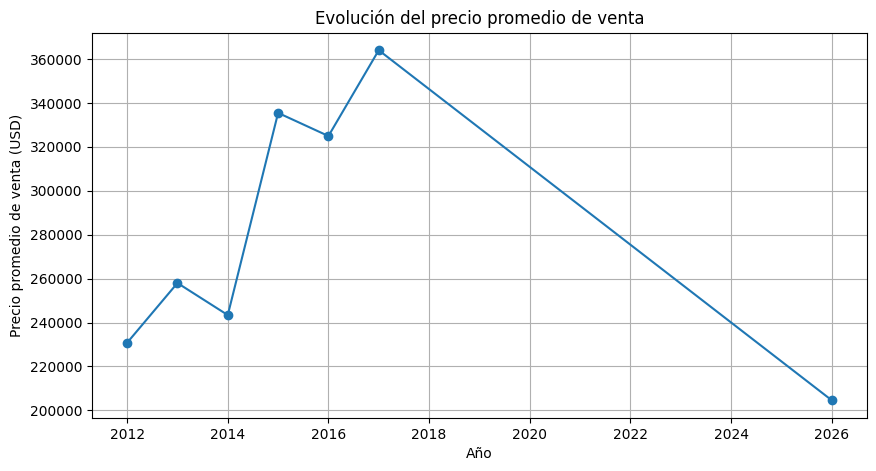

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    precio_venta_por_año.index,
    precio_venta_por_año.values,
    marker="o"
)

plt.title("Evolución del precio promedio de venta")
plt.xlabel("Año")
plt.ylabel("Precio promedio de venta (USD)")

plt.grid(True)
plt.show()

### Conclusión

Entre 2012 y 2017 se observan fluctuaciones en el precio promedio de venta de las propiedades, alcanzándose el valor más elevado del período disponible en 2017. En 2026, el precio promedio de venta registrado en el dataset es inferior al observado en 2017.

Sin embargo, la base no contiene registros correspondientes al período comprendido entre 2018 y 2025. Por este motivo, no es posible determinar cómo evolucionaron los precios de venta durante esos años ni interpretar la línea que une 2017 con 2026 como una caída continua del mercado.

Los registros correspondientes a alquileres fueron separados de este análisis debido a que la información disponible no permite determinar con certeza la periodicidad asociada a los valores de precio informados, evitando así comparar directamente magnitudes que podrían no ser equivalentes.

In [ ]:
usd_m2_venta_por_año = ventas.groupby("año")["usd_m2_prom"].mean()
usd_m2_alquiler_por_año = alquileres.groupby("año")["usd_m2_prom"].mean()

print("USD/m² PROMEDIO DE VENTA POR AÑO")
print(usd_m2_venta_por_año)

print("\nUSD/m² PROMEDIO DE ALQUILER POR AÑO")
print(usd_m2_alquiler_por_año)

USD/m² PROMEDIO DE VENTA POR AÑO
año
2012    2095.902439
2013    2034.224490
2014    1916.761364
2015    2029.978610
2016    2008.947674
2017    2127.451613
2026    1395.500000
Name: usd_m2_prom, dtype: float64

USD/m² PROMEDIO DE ALQUILER POR AÑO
año
2012    1846.827586
2013    1812.240741
2014    1683.466667
2015    2038.933333
2016    2496.779661
2017    2278.346939
2026    1748.554455
Name: usd_m2_prom, dtype: float64


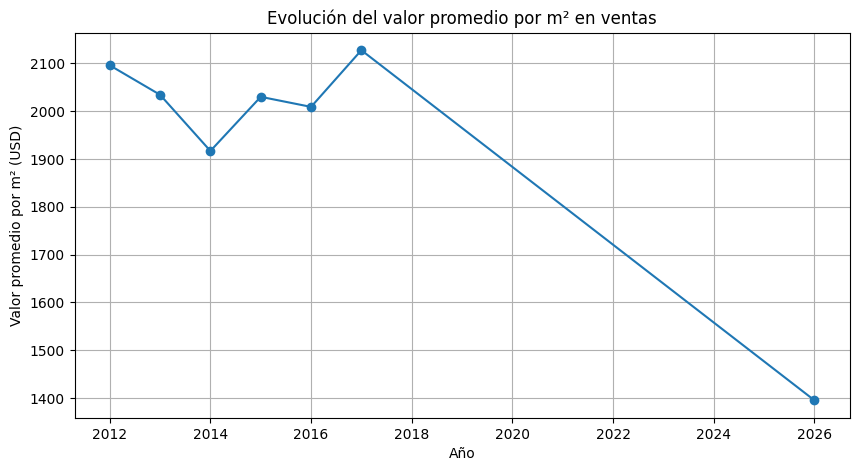

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    usd_m2_venta_por_año.index,
    usd_m2_venta_por_año.values,
    marker="o"
)

plt.title("Evolución del valor promedio por m² en ventas")
plt.xlabel("Año")
plt.ylabel("Valor promedio por m² (USD)")

plt.grid(True)
plt.show()

### Conclusión

Entre 2012 y 2017, el valor promedio por metro cuadrado de las propiedades en venta presenta fluctuaciones, manteniéndose dentro de un rango relativamente estable durante los años disponibles y alcanzando su valor más elevado en 2017.

En 2026 se observa un valor promedio por metro cuadrado inferior al registrado en los años anteriores disponibles. Sin embargo, debido a que el dataset no contiene registros correspondientes al período 2018–2025, no es posible determinar cómo evolucionó esta variable durante esos años ni interpretar la línea que une 2017 con 2026 como una disminución continua.

Los registros correspondientes a alquileres se mantienen separados de este análisis para evitar comparar directamente valores cuya interpretación y periodicidad no se encuentran suficientemente especificadas en la información disponible.

### Pregunta 2: Diferencias de precios según ubicación y tipo de propiedad
En primer lugar, se analizará el precio promedio de las propiedades según su tipo, con el objetivo de identificar posibles diferencias entre departamentos, casas, PH, locales y lofts.
Debido a que se busca comparar una variable numérica entre distintas categorías, se utilizará un gráfico de barras.

In [ ]:
precio_venta_por_tipo = ventas.groupby("tipo_propiedad")["precio_usd_prom"].mean()

precio_venta_por_tipo = precio_venta_por_tipo.sort_values(ascending=False)

precio_venta_por_tipo

,precio_usd_prom
tipo_propiedad,
Local,497005.186992
Casa,439711.672078
Departamento,174831.807580
PH,168538.820261
Loft,136129.041667


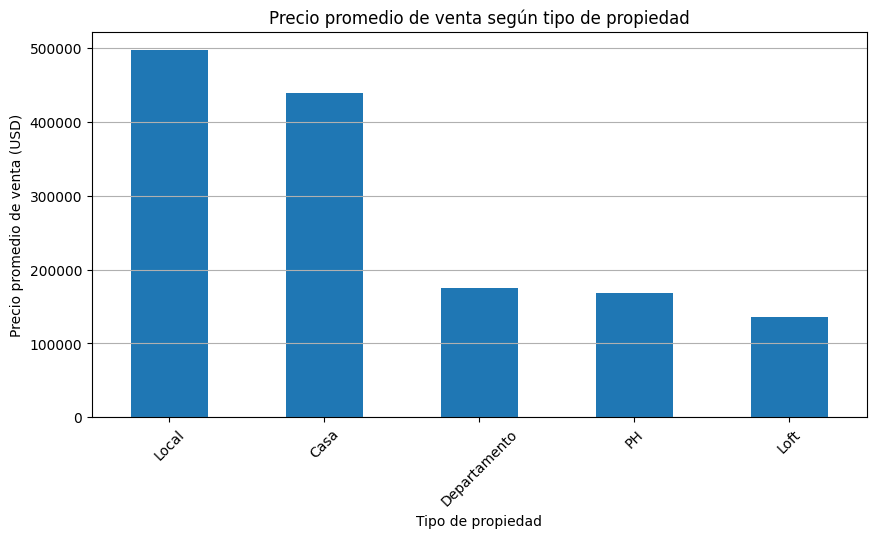

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

precio_venta_por_tipo.plot(kind="bar")

plt.title("Precio promedio de venta según tipo de propiedad")
plt.xlabel("Tipo de propiedad")
plt.ylabel("Precio promedio de venta (USD)")

plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()

In [ ]:
data_set_limpio["barrio"] = data_set_limpio["barrio"].replace({
    "AGRONOMÍA": "AGRONOMIA",
    "NUÑEZ": "NUNEZ",
    "NUEZ": "NUNEZ"
})

In [ ]:
ventas = data_set_limpio[data_set_limpio["tipo_operacion"] == "VENTA"].copy()

In [ ]:
data_set_limpio["barrio"].nunique()

84

In [ ]:
precio_venta_por_barrio = ventas[
    ventas["barrio"] != "CAPITAL FEDERAL"
].groupby("barrio")["precio_usd_prom"].mean()

top10_precio_venta_barrio = (
    precio_venta_por_barrio
    .sort_values(ascending=False)
    .head(10)
)

top10_precio_venta_barrio

,precio_usd_prom
barrio,
PUERTO MADERO,998807.000000
PALERMO CHICO,954172.916667
RECOLETA,588931.333333
VILLA SOLDATI,584531.600000
RETIRO,584109.000000
VILLA ORTUZAR,583292.043478
PALERMO,505245.086957
BELGRANO,465429.409091
PALERMO SOHO,459892.666667


In [ ]:
data_set_limpio[
    data_set_limpio["barrio"].str.contains("NU", case=False, na=False)
]["barrio"].value_counts()

,count
barrio,
NUNEZ,28
NUEVA POMPEYA,7
MANUEL ALBERTI,1


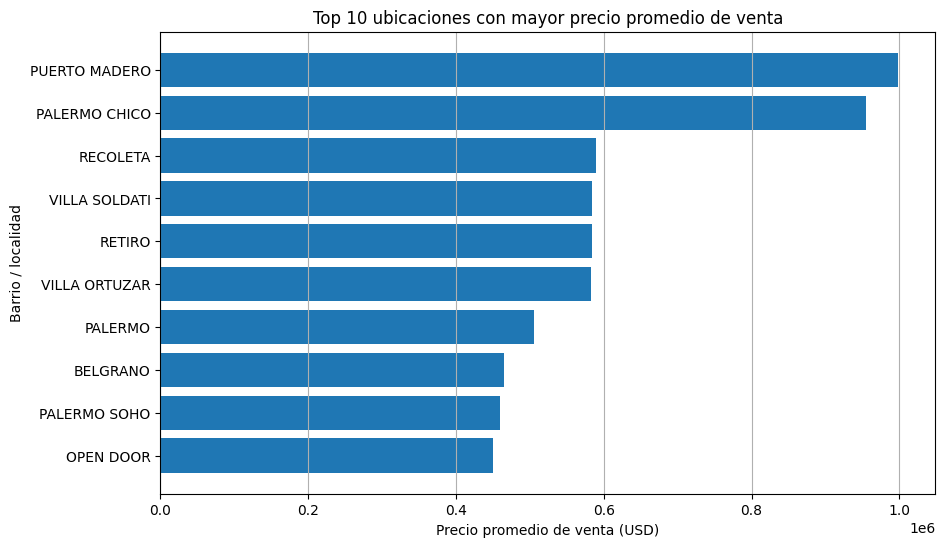

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    top10_precio_venta_barrio.index,
    top10_precio_venta_barrio.values
)

plt.title("Top 10 ubicaciones con mayor precio promedio de venta")
plt.xlabel("Precio promedio de venta (USD)")
plt.ylabel("Barrio / localidad")

plt.grid(axis="x")
plt.gca().invert_yaxis()

plt.show()

### Conclusión

Al analizar exclusivamente las operaciones de venta, se observan diferencias importantes en el precio promedio según la ubicación. Puerto Madero y Palermo Chico presentan los precios promedio de venta más elevados, con valores considerablemente superiores al resto de las ubicaciones analizadas. A partir de Recoleta, los precios promedio disminuyen de manera significativa.

Estos resultados muestran que la ubicación constituye un factor relevante en el precio de venta de las propiedades. Sin embargo, los valores deben interpretarse considerando también otras características, como el tipo de propiedad, la superficie, la antigüedad y el estado del inmueble.

In [ ]:
usd_m2_venta_por_tipo = ventas.groupby("tipo_propiedad")["usd_m2_prom"].mean()

usd_m2_venta_por_tipo = usd_m2_venta_por_tipo.sort_values(ascending=False)

usd_m2_venta_por_tipo

,usd_m2_prom
tipo_propiedad,
Local,2583.281633
Departamento,2303.306122
Loft,1939.833333
PH,1608.052288
Casa,1587.139610


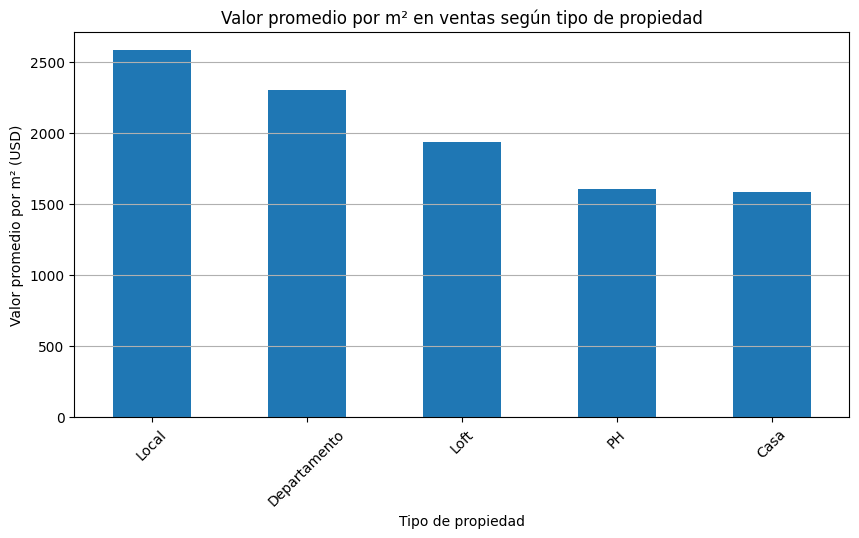

In [ ]:
plt.figure(figsize=(10, 5))

usd_m2_venta_por_tipo.plot(kind="bar")

plt.title("Valor promedio por m² en ventas según tipo de propiedad")
plt.xlabel("Tipo de propiedad")
plt.ylabel("Valor promedio por m² (USD)")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.show()

### Conclusión

Al analizar exclusivamente las operaciones de venta, se observan diferencias en el valor promedio por metro cuadrado según el tipo de propiedad. Los locales presentan el valor promedio por m² más elevado, seguidos por los departamentos y los lofts. En cambio, los PH y las casas presentan los valores promedio por m² más bajos.

Estos resultados muestran que el tipo de propiedad se relaciona con diferencias en el valor por metro cuadrado. Sin embargo, estas diferencias también pueden estar asociadas a otros factores, como la ubicación, la superficie, la antigüedad y el estado de las propiedades.

In [ ]:
usd_m2_venta_por_barrio = ventas[
    ventas["barrio"] != "CAPITAL FEDERAL"
].groupby("barrio")["usd_m2_prom"].mean()

top10_usd_m2_venta_barrio = usd_m2_venta_por_barrio.sort_values(
    ascending=False
).head(10)

top10_usd_m2_venta_barrio

,usd_m2_prom
barrio,
PALERMO CHICO,4542.916667
PUERTO MADERO,4495.111111
PALERMO,3236.304348
RECOLETA,3083.291667
PALERMO SOHO,3041.888889
PALERMO VIEJO,3023.384615
LAS CAÑITAS,2946.307692
VILLA CRESPO,2935.391304
RETIRO,2900.937500


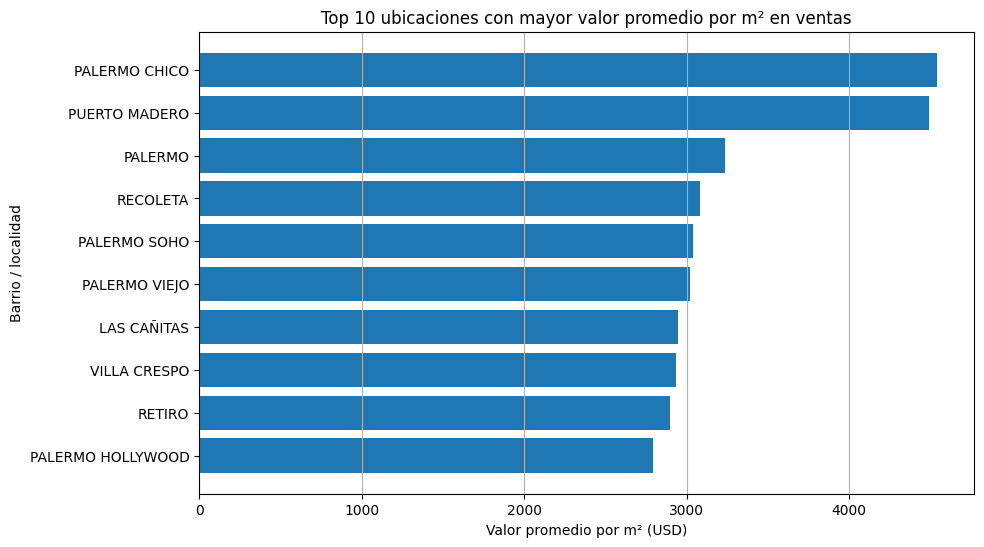

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    top10_usd_m2_venta_barrio.index,
    top10_usd_m2_venta_barrio.values
)

plt.title("Top 10 ubicaciones con mayor valor promedio por m² en ventas")
plt.xlabel("Valor promedio por m² (USD)")
plt.ylabel("Barrio / localidad")

plt.grid(axis="x")
plt.gca().invert_yaxis()

plt.show()

### Conclusión

Al analizar exclusivamente las operaciones de venta, se observan diferencias en el valor promedio por metro cuadrado según el tipo de propiedad. Los locales presentan el mayor valor promedio por m², seguidos por los departamentos y los lofts, mientras que los PH y las casas registran valores inferiores.

En cuanto a la ubicación, Palermo Chico y Puerto Madero presentan los mayores valores promedio por metro cuadrado dentro de las ubicaciones analizadas. También se destacan Palermo, Recoleta, Palermo Soho, Palermo Viejo, Las Cañitas, Villa Crespo, Retiro y Palermo Hollywood.

Estos resultados muestran que el precio total de venta de una propiedad y su valor por metro cuadrado no necesariamente presentan el mismo comportamiento. Por ejemplo, las casas poseen un precio total promedio elevado, pero presentan el menor valor promedio por m² entre los tipos de propiedad analizados. Esto indica que ambas métricas aportan información complementaria para comprender el mercado inmobiliario.

Para el análisis por ubicación se excluyó la categoría CAPITAL FEDERAL, debido a que representa una agrupación geográfica general y no un barrio o localidad específica, manteniéndose dichos registros en el dataset para otros análisis.


## Pregunta 3: Relación entre la superficie y el precio de las propiedades

Con el objetivo de responder la tercera pregunta de análisis, se estudiará la relación entre la superficie de las propiedades y su precio promedio.

En este caso se analizarán dos variables numéricas: la superficie total promedio (`m2_total_prom`) y el precio promedio de las propiedades (`precio_usd_prom`).

Para evaluar la relación entre ambas variables se utilizará un gráfico de dispersión, que permitirá observar si existe una tendencia entre el tamaño de las propiedades y su precio, así como identificar posibles valores atípicos.

In [ ]:
ventas[["m2_total_prom", "precio_usd_prom"]].quantile([0.90, 0.95, 0.99])

,m2_total_prom,precio_usd_prom
0.90,368.0,582109.4
0.95,499.5,799250.0
0.99,1268.0,1947757.6


In [ ]:
ventas_superficie = ventas[ventas["m2_total_prom"] > 0]

ventas_scatter_95 = ventas_superficie[
    (ventas_superficie["m2_total_prom"] <= 499.5) &
    (ventas_superficie["precio_usd_prom"] <= 799250.0)
]

ventas_scatter_95.shape

(1123, 19)

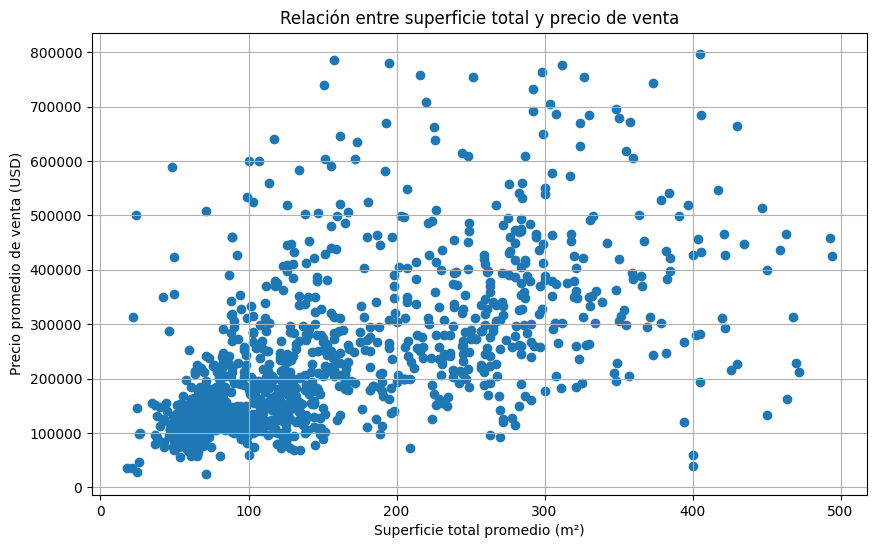

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
    ventas_scatter_95["m2_total_prom"],
    ventas_scatter_95["precio_usd_prom"]
)

plt.title("Relación entre superficie total y precio de venta")
plt.xlabel("Superficie total promedio (m²)")
plt.ylabel("Precio promedio de venta (USD)")

plt.grid(True)
plt.show()

In [ ]:
ventas_scatter_95["m2_total_prom"].corr(
    ventas_scatter_95["precio_usd_prom"]
)

np.float64(0.5947202588952839)

### Conclusión

El gráfico de dispersión permite observar una tendencia positiva entre la superficie total promedio y el precio promedio de venta de las propiedades.

Luego de limitar el análisis a los registros cuyos valores de superficie total promedio y precio promedio de venta se encuentran por debajo o dentro de sus respectivos percentiles 95, con el objetivo de reducir el efecto visual de los valores extremos, se obtuvo un coeficiente de correlación de aproximadamente **0,59** entre ambas variables. Este resultado indica una **correlación positiva moderada**.

Por lo tanto, dentro de las operaciones de venta analizadas, las propiedades de mayor superficie tienden a presentar precios de venta más elevados. Sin embargo, la relación no es perfecta, lo que indica que el precio también se encuentra asociado a otras características de las propiedades, como su ubicación, tipo, estado y antigüedad.

Los valores extremos no fueron eliminados del dataset original, sino que fueron excluidos únicamente de esta visualización para facilitar la interpretación del gráfico.

## Pregunta 4: Influencia de cochera y amenities en el precio

A continuación se analizará si existen diferencias en el precio promedio de las propiedades según la disponibilidad de cochera y amenities.

Para ello, se comparará el precio promedio de las propiedades que poseen estas características con aquellas que no las poseen, utilizando gráficos de barras para facilitar la comparación entre las categorías.

In [ ]:
precio_venta_por_cochera = ventas.groupby("cochera")["precio_usd_prom"].mean()

precio_venta_por_cochera

,precio_usd_prom
cochera,
NO,293586.549774
SI,329362.236152


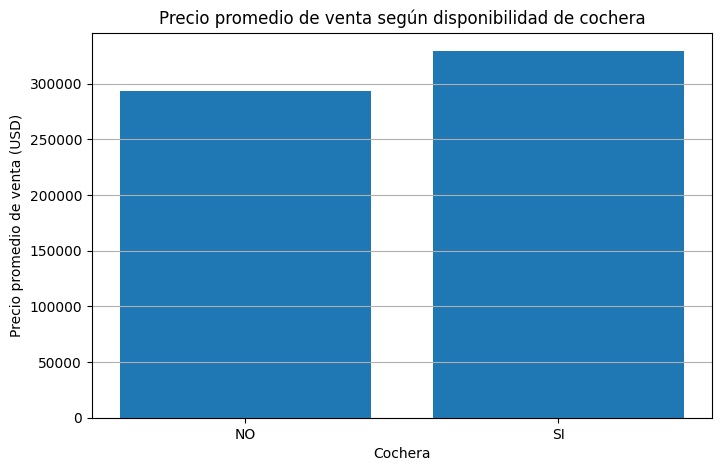

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    precio_venta_por_cochera.index,
    precio_venta_por_cochera.values
)

plt.title("Precio promedio de venta según disponibilidad de cochera")
plt.xlabel("Cochera")
plt.ylabel("Precio promedio de venta (USD)")

plt.grid(axis="y")
plt.show()

In [ ]:
precio_venta_por_amenities = ventas.groupby("amenities")["precio_usd_prom"].mean()

precio_venta_por_amenities

,precio_usd_prom
amenities,
NO,320908.424899
SI,277357.440574


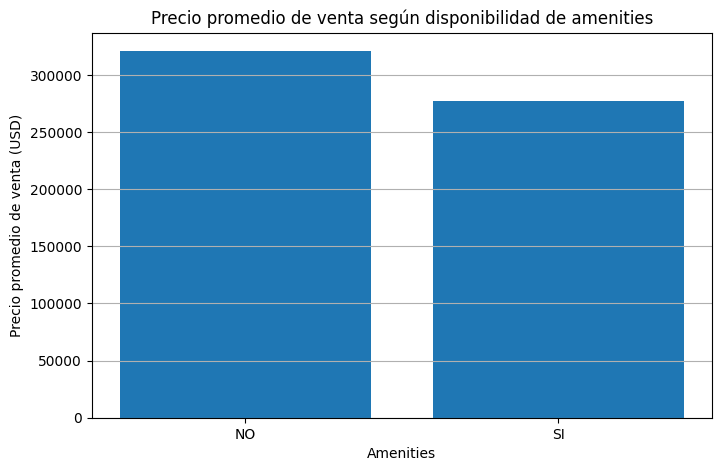

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    precio_venta_por_amenities.index,
    precio_venta_por_amenities.values
)

plt.title("Precio promedio de venta según disponibilidad de amenities")
plt.xlabel("Amenities")
plt.ylabel("Precio promedio de venta (USD)")

plt.grid(axis="y")
plt.show()

### Conclusión

El análisis de las operaciones de venta muestra diferencias en el precio promedio de las propiedades según la disponibilidad de cochera y amenities.

En el caso de la **cochera**, las propiedades que cuentan con ella presentan un precio promedio de venta aproximado de **USD 329.362**, mientras que aquellas que no poseen cochera registran un promedio cercano a **USD 293.587**. Por lo tanto, dentro del dataset analizado, la presencia de cochera se encuentra asociada a un mayor precio promedio de venta.

En cambio, para los **amenities** se observa un comportamiento diferente. Las propiedades sin amenities presentan un precio promedio de venta aproximado de **USD 320.908**, superior al promedio de aproximadamente **USD 277.357** correspondiente a las propiedades que sí poseen amenities.

Estos resultados deben interpretarse como **asociaciones y no como relaciones causales**, ya que el precio de una propiedad también puede estar relacionado con otras características como la ubicación, la superficie, el tipo de propiedad, su estado y antigüedad.

Por lo tanto, a partir de los datos disponibles, la presencia de cochera se asocia con un mayor precio promedio de venta, mientras que la disponibilidad de amenities no presenta el mismo comportamiento.

## Pregunta 5: Distribución según tipo de propiedad y tipo de operación

A continuación se analizará la distribución de los registros según el tipo de propiedad y el tipo de operación.

Dado que ambas variables son categóricas, se analizará la frecuencia de las distintas combinaciones entre tipo de propiedad y operación, permitiendo comparar la participación de las operaciones de venta y alquiler para cada tipo de inmueble.

In [ ]:
distribucion_propiedad_operacion = data_set_limpio.groupby(
    ["tipo_propiedad", "tipo_operacion"]
).size()

distribucion_propiedad_operacion

tipo_propiedad  tipo_operacion
Casa            ALQUILER          106
                VENTA             308
Departamento    ALQUILER          123
                VENTA             343
Local           ALQUILER           47
                VENTA             246
Loft            ALQUILER            8
                VENTA              24
PH              ALQUILER           99
                VENTA             306
dtype: int64

In [ ]:
distribucion_tabla = distribucion_propiedad_operacion.unstack()

distribucion_tabla

tipo_operacion,ALQUILER,VENTA
tipo_propiedad,,
Casa,106,308
Departamento,123,343
Local,47,246
Loft,8,24
PH,99,306


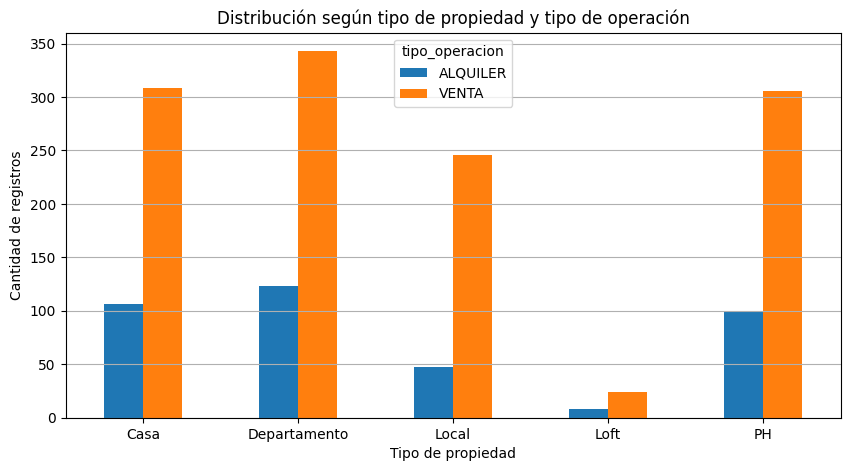

In [ ]:
distribucion_tabla.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Distribución según tipo de propiedad y tipo de operación")
plt.xlabel("Tipo de propiedad")
plt.ylabel("Cantidad de registros")

plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

### Conclusión

La distribución de los registros muestra un claro predominio de los registros correspondientes a operaciones de venta sobre los de alquiler para todos los tipos de propiedad analizados.

Los departamentos presentan la mayor cantidad de registros, con 343 correspondientes a ventas y 123 a alquileres, seguidos por las casas y los PH. Los locales también presentan una mayor cantidad de registros asociados a ventas, mientras que los lofts constituyen el tipo de propiedad con menor cantidad de registros dentro del dataset.

En términos generales, los resultados indican que la base de datos utilizada posee una mayor representación de registros correspondientes a propiedades en venta que en alquiler. Debido a la estructura agregada del dataset, estas cantidades representan registros y no necesariamente propiedades individuales.

# Síntesis final

El análisis realizado permitió identificar distintos patrones en el mercado inmobiliario representado por el dataset, considerando especialmente las operaciones de venta para aquellos análisis relacionados con precios.

En relación con la evolución temporal, se observaron fluctuaciones tanto en el precio promedio de venta como en el valor promedio por metro cuadrado durante los años disponibles. Sin embargo, la ausencia de registros entre 2018 y 2025 impide interpretar la evolución entre 2017 y 2026 como una tendencia continua.

También se identificaron diferencias importantes según el tipo de propiedad y la ubicación. Los locales presentan el mayor valor promedio por metro cuadrado entre los tipos de propiedad analizados, mientras que Palermo Chico y Puerto Madero se destacan entre las ubicaciones con mayores valores promedio por m² en las operaciones de venta.

Por otra parte, se observó una correlación positiva moderada, de aproximadamente **0,59**, entre la superficie total promedio y el precio promedio de venta, indicando que las propiedades de mayor superficie tienden a presentar precios más elevados, aunque existen otros factores que también influyen en su valoración.

Respecto de las características de las propiedades, la disponibilidad de cochera se encuentra asociada a un mayor precio promedio de venta. En cambio, las propiedades con amenities no presentan un precio promedio superior dentro del conjunto analizado. Estos resultados representan asociaciones observadas en los datos y no deben interpretarse como relaciones causales.

Finalmente, la distribución de los registros muestra un predominio de las operaciones de venta sobre las de alquiler para todos los tipos de propiedad considerados. Debido a que el dataset posee una estructura agregada, estas cantidades representan registros que pueden agrupar varias propiedades y no necesariamente inmuebles individuales.

En conjunto, los resultados permiten caracterizar distintos aspectos del mercado inmobiliario presente en la base y constituyen una base para el desarrollo posterior de un tablero interactivo que permita explorar la información según ubicación, tipo de propiedad y tipo de operación.

In [ ]:
data_set_limpio.to_excel(
    "Dataset_Real_Estate_Limpio.xlsx",
    index=False
)

from google.colab import files
files.download("Dataset_Real_Estate_Limpio.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>